In [ ]:
                                     ASSIGNMENT 2

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [10]:
data = pd.read_csv("emails.csv")



In [11]:
data.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [12]:
data.tail()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
5167,Email 5168,2,2,2,3,0,0,32,0,0,...,0,0,0,0,0,0,0,0,0,0
5168,Email 5169,35,27,11,2,6,5,151,4,3,...,0,0,0,0,0,0,0,1,0,0
5169,Email 5170,0,0,1,1,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,1
5170,Email 5171,2,7,1,0,2,1,28,2,0,...,0,0,0,0,0,0,0,1,0,1
5171,Email 5172,22,24,5,1,6,5,148,8,2,...,0,0,0,0,0,0,0,0,0,0


In [13]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB


In [14]:
print(data.shape)
print(data.columns)

(5172, 3002)
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)


In [15]:
print(data["Prediction"].value_counts())

Prediction
0    3672
1    1500
Name: count, dtype: int64


In [16]:
X = data.drop("Prediction", axis=1)
y = data["Prediction"]

print(X.shape)
print(y.shape)

(5172, 3001)
(5172,)


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4137, 3001)
Testing data: (1035, 3001)


In [20]:
X = data.drop("Prediction", axis=1)
y = data["Prediction"]

X = X.select_dtypes(include="number")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("KNN Precision:", precision_score(y_test, y_pred_knn))
print("KNN Recall:", recall_score(y_test, y_pred_knn))
print("KNN F1 Score:", f1_score(y_test, y_pred_knn))

KNN Accuracy: 0.8714975845410629
KNN Precision: 0.7448680351906158
KNN Recall: 0.8466666666666667
KNN F1 Score: 0.7925117004680188


In [21]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("KNN Confusion Matrix:")
print(cm_knn)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

KNN Confusion Matrix:
[[648  87]
 [ 46 254]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.88      0.91       735
           1       0.74      0.85      0.79       300

    accuracy                           0.87      1035
   macro avg       0.84      0.86      0.85      1035
weighted avg       0.88      0.87      0.87      1035



In [23]:
svm = SVC(kernel="linear")

svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("SVM Precision:", precision_score(y_test, y_pred_svm))
print("SVM Recall:", recall_score(y_test, y_pred_svm))
print("SVM F1 Score:", f1_score(y_test, y_pred_svm))

SVM Accuracy: 0.9671497584541063
SVM Precision: 0.9375
SVM Recall: 0.95
SVM F1 Score: 0.9437086092715232


In [24]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("SVM Confusion Matrix:")
print(cm_svm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Confusion Matrix:
[[716  19]
 [ 15 285]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       735
           1       0.94      0.95      0.94       300

    accuracy                           0.97      1035
   macro avg       0.96      0.96      0.96      1035
weighted avg       0.97      0.97      0.97      1035



In [25]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("KNN Accuracy:", knn_accuracy)
print("SVM Accuracy:", svm_accuracy)

if svm_accuracy > knn_accuracy:
    print("SVM performs better than KNN")
else:
    print("KNN performs better than SVM")

KNN Accuracy: 0.8714975845410629
SVM Accuracy: 0.9671497584541063
SVM performs better than KNN


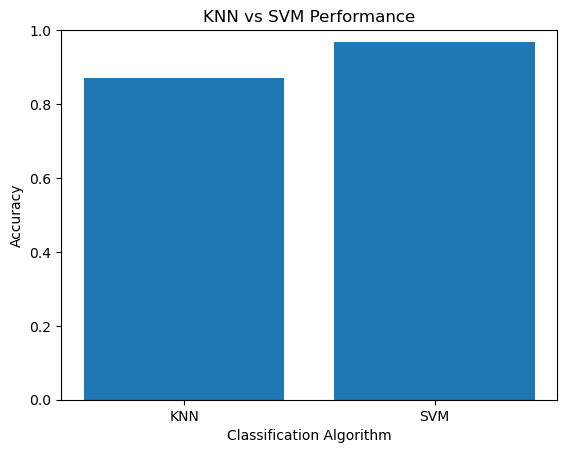

In [26]:
models = ["KNN", "SVM"]
accuracy = [knn_accuracy, svm_accuracy]

plt.bar(models, accuracy)
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy")
plt.title("KNN vs SVM Performance")
plt.ylim(0, 1)
plt.show()

In [27]:
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm)
    ]
})

print(results)

  Model  Accuracy  Precision    Recall  F1 Score
0   KNN  0.871498   0.744868  0.846667  0.792512
1   SVM  0.967150   0.937500  0.950000  0.943709
